<a href="https://colab.research.google.com/github/MOHAMEDAAKIFASRAR/TSA_EXP2/blob/main/TSA_EXP_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Linear Trend Equation
y = 281.63 + (2.66)X


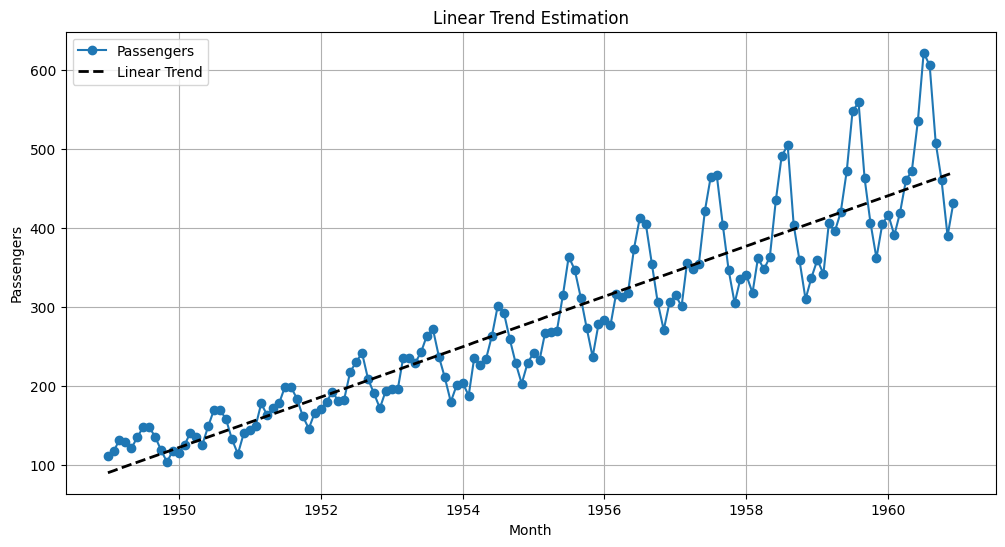

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/AirPassengers.csv")

df["Month"] = pd.to_datetime(df["Month"])
df = df.dropna(subset=["#Passengers"])

df = df.reset_index(drop=True)

period = df["Month"]
passengers = df["#Passengers"].tolist()

n = len(passengers)

X = [i - n//2 for i in range(n)]
x2 = [i**2 for i in X]
xy = [i*j for i, j in zip(X, passengers)]

b = (n*sum(xy) - sum(passengers)*sum(X)) / (n*sum(x2) - (sum(X)**2))
a = (sum(passengers) - b*sum(X)) / n

linear_trend = [a + b*X[i] for i in range(n)]

print("Linear Trend Equation")
print(f"y = {a:.2f} + ({b:.2f})X")

plt.figure(figsize=(12,6))
plt.plot(period, passengers, marker='o', label="Passengers")
plt.plot(period, linear_trend, 'k--', linewidth=2, label="Linear Trend")

plt.title("Linear Trend Estimation")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.show()

Polynomial Trend Equation
y = 269.52 + (2.66)X + (0.01)X²


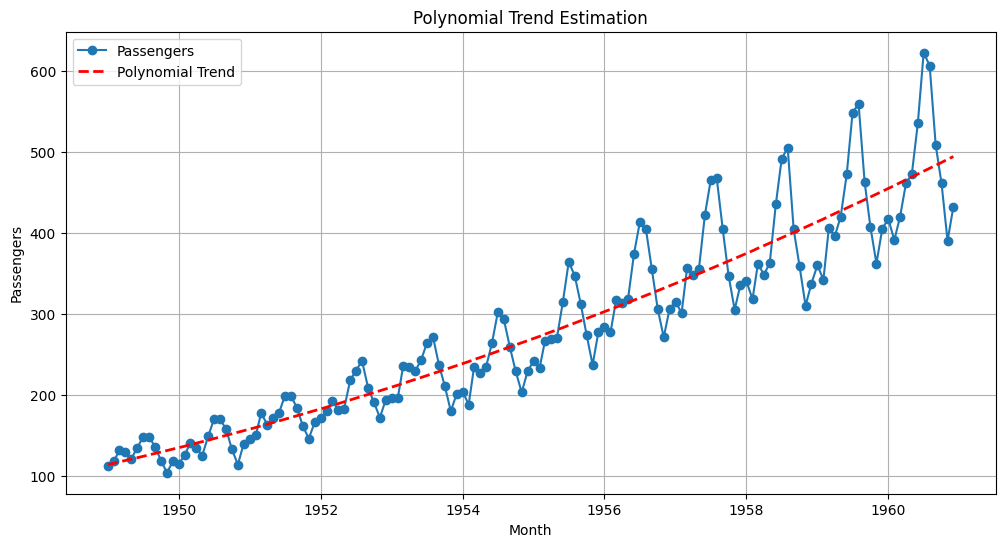

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/AirPassengers.csv")

df["Month"] = pd.to_datetime(df["Month"])
df = df.dropna(subset=["#Passengers"])

df = df.reset_index(drop=True)

period = df["Month"]
passengers = df["#Passengers"].tolist()

n = len(passengers)

X = [i - n//2 for i in range(n)]
x2 = [i**2 for i in X]
xy = [i*j for i, j in zip(X, passengers)]

x3 = [i**3 for i in X]
x4 = [i**4 for i in X]
x2y = [i*j for i, j in zip(x2, passengers)]

coeff = [
    [n, sum(X), sum(x2)],
    [sum(X), sum(x2), sum(x3)],
    [sum(x2), sum(x3), sum(x4)]
]

Y = [
    sum(passengers),
    sum(xy),
    sum(x2y)
]

A = np.array(coeff)
B = np.array(Y)

a_poly, b_poly, c_poly = np.linalg.solve(A, B)

poly_trend = [
    a_poly + b_poly*X[i] + c_poly*(X[i]**2)
    for i in range(n)
]

print("Polynomial Trend Equation")
print(f"y = {a_poly:.2f} + ({b_poly:.2f})X + ({c_poly:.2f})X²")

plt.figure(figsize=(12,6))
plt.plot(period, passengers, marker='o', label="Passengers")
plt.plot(period, poly_trend, 'r--', linewidth=2, label="Polynomial Trend")

plt.title("Polynomial Trend Estimation")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.show()